# LSTM — Previsão do Preço Diário do Arroz com Variáveis Exógenas

**TCC — Sistemas de Informação | PUCRS**
Bruno Origem Noronha

Este notebook implementa uma rede neural recorrente **LSTM** (*Long Short-Term Memory*) para prever o **preço diário do arroz**
(`preco_brl`, R$ / saca 50 kg) a partir de uma **janela dos últimos 30 dias** com **todas as 36 variáveis** do dataset integrado:
defasagens e estatísticas móveis do preço, câmbio, IPCA, Selic, clima e calendário.

Diferente do SARIMA/SARIMAX, que são modelos **lineares** com estrutura definida a priori, a LSTM **aprende** a partir dos dados
relações **não lineares** e dependências de longo prazo, graças às suas "portas" (esquecimento, entrada e saída) que controlam
o que a célula de memória guarda ou descarta ao longo da sequência.

Roteiro:
1. Carregamento do dataset integrado e seleção das variáveis
2. Divisão cronológica (treino até 31/01/2026 — teste nos 30 dias seguintes)
3. Normalização (`MinMaxScaler` ajustado só no treino) e janelamento (`lookback = 30`)
4. Arquitetura e treinamento da LSTM (Keras)
5. Previsão no teste, `inverse_transform` e métricas (RMSE, MAE, MAPE)
6. Visualização gráfica e exportação

In [1]:
# Bibliotecas
import os
import random
import warnings
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # esconde mensagens internas do TensorFlow

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from sklearn.preprocessing import MinMaxScaler

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Reprodutibilidade: fixa as sementes aleatórias (pesos iniciais, dropout)
SEMENTE = 42
random.seed(SEMENTE)
np.random.seed(SEMENTE)
tf.random.set_seed(SEMENTE)
tf.config.experimental.enable_op_determinism()

# Pasta onde salvamos o gráfico e as métricas
PASTA_SAIDA = "outputs"
os.makedirs(PASTA_SAIDA, exist_ok=True)

print(f"TensorFlow {tf.__version__}")

TensorFlow 2.21.0


## 1. Carregamento e seleção das variáveis

Usamos o **dataset integrado** `dataset_final_arroz.csv`, já em frequência diária e sem valores ausentes.

- **Alvo (y):** `preco_brl`.
- **Entradas (X):** **todas as demais colunas** — removemos apenas a data (que vira índice) e o próprio alvo. São 36 variáveis:

| Grupo | Variáveis |
|---|---|
| **Preço (engenharia de atributos)** | `preco_usd`, defasagens `preco_brl_lag_1/7/14/30`, médias móveis `preco_brl_ma_7/14/30` e volatilidades `preco_brl_std_7/14/30` |
| **Câmbio** | `dolar_venda`, `dolar_lag_1/7/14`, `dolar_ma_7/30` |
| **Macroeconomia** | `ipca_indice`, `ipca_mensal`, `ipca_12m`, `selic_ad`, `selic_aa` |
| **Clima** | `precipitacao_mm`, `precipitacao_acc_7/15/30`, `temp_ar_c`, `temp_max_c`, `temp_min_c`, `umidade_relativa` |
| **Calendário** | `mes`, `dia_ano`, `sin_mes`, `cos_mes`, `sin_dia_ano`, `cos_dia_ano` |

> **Sem vazamento de informação:** a janela de entrada termina no dia $t$ e o alvo é o preço de $t+1$. Variáveis como
> `preco_brl_ma_7` incluem o preço do próprio dia da linha, mas como a última linha da janela é $t$, nenhuma informação de $t+1$ entra no X.

In [2]:
dados = pd.read_csv("../data/processed/dataset_final_arroz.csv", parse_dates=["data"], index_col="data").asfreq("D")

ALVO     = "preco_brl"
FEATURES = [c for c in dados.columns if c != ALVO]   # todas as colunas, exceto o alvo (a data já é o índice)

print(f"Valores ausentes: {dados.isna().sum().sum()}")
print(f"Período total: {dados.index[0]:%d/%m/%Y} a {dados.index[-1]:%d/%m/%Y} ({len(dados)} dias)")
print(f"Número de variáveis de entrada (X): {len(FEATURES)}")
print(", ".join(FEATURES))
assert len(FEATURES) == 36 and ALVO not in FEATURES

Valores ausentes: 0
Período total: 01/02/2008 a 20/04/2026 (6654 dias)
Número de variáveis de entrada (X): 36
preco_usd, precipitacao_mm, temp_ar_c, temp_max_c, temp_min_c, umidade_relativa, dolar_venda, ipca_indice, ipca_mensal, ipca_12m, selic_ad, selic_aa, mes, dia_ano, sin_mes, cos_mes, sin_dia_ano, cos_dia_ano, preco_brl_lag_1, preco_brl_lag_7, preco_brl_lag_14, preco_brl_lag_30, preco_brl_ma_7, preco_brl_std_7, preco_brl_ma_14, preco_brl_std_14, preco_brl_ma_30, preco_brl_std_30, dolar_lag_1, dolar_lag_7, dolar_lag_14, dolar_ma_7, dolar_ma_30, precipitacao_acc_7, precipitacao_acc_15, precipitacao_acc_30


## 2. Divisão cronológica: treino vs. teste

| Conjunto | Período | Observação |
|---|---|---|
| **Treino** | início da série até **31/01/2026** | inclui choques como a pandemia (2020) e as enchentes no RS (2024) |
| **Teste** | **30 dias** consecutivos a partir de **01/02/2026** | horizonte de curto prazo |

Dentro do treino, os **últimos 10% das janelas** são separados como **validação**, usada apenas pelo `EarlyStopping`
para decidir quando parar de treinar. Também é uma divisão cronológica: nenhuma informação do futuro entra no ajuste.

In [3]:
FIM_TREINO = "2026-01-31"
HORIZONTE  = 30
LOOKBACK   = 30   # dias de histórico em cada janela

treino = dados.loc[:FIM_TREINO]
teste  = dados.loc["2026-02-01":].iloc[:HORIZONTE]

print(f"Treino: {len(treino)} dias ({treino.index[0]:%d/%m/%Y} a {treino.index[-1]:%d/%m/%Y})")
print(f"Teste : {len(teste)} dias ({teste.index[0]:%d/%m/%Y} a {teste.index[-1]:%d/%m/%Y})")

Treino: 6575 dias (01/02/2008 a 31/01/2026)
Teste : 30 dias (01/02/2026 a 02/03/2026)


## 3. Normalização e janelamento

### 3.1 Normalização com `MinMaxScaler(0, 1)`

Redes neurais treinam melhor com entradas na mesma escala: sem isso, o preço (~R$ 60) e o seno do mês (entre -1 e 1)
teriam pesos muito desbalanceados no gradiente. Com 36 variáveis em escalas muito diferentes (IPCA índice ~7.000, Selic diária ~0,05),
a normalização é ainda mais importante.

Para **evitar data leakage**, o `fit` dos escaladores usa **apenas o treino**; o teste é só transformado com os mínimos e máximos
do treino. Usamos dois escaladores:

- `escala_X` — as 36 variáveis de entrada (cada coluna tem seu próprio mínimo e máximo, ou seja, a escala é independente por coluna);
- `escala_y` — apenas o alvo, para depois **desfazer a escala** (`inverse_transform`) das previsões e voltar para R\$.

> No teste, valores fora da faixa do treino podem ficar um pouco abaixo de 0 ou acima de 1. Isso é esperado e não é um problema.

In [4]:
escala_X = MinMaxScaler(feature_range=(0, 1)).fit(treino[FEATURES])
escala_y = MinMaxScaler(feature_range=(0, 1)).fit(treino[[ALVO]])

# Série completa (treino + teste) transformada com os parâmetros do treino
X_esc = escala_X.transform(dados.loc[:teste.index[-1], FEATURES])
y_esc = escala_y.transform(dados.loc[:teste.index[-1], [ALVO]]).ravel()
datas = dados.loc[:teste.index[-1]].index

print("Faixa do treino escalado:", X_esc[:len(treino)].min().round(3), "a", X_esc[:len(treino)].max().round(3))

Faixa do treino escalado: 0.0 a 1.0


### 3.2 Janela deslizante (`lookback = 30`)

Cada amostra é uma **sequência dos 30 dias anteriores** (todas as variáveis) e o rótulo é o **preço do dia seguinte** ($t+1$):

$$\big[\,x_{t-29},\; x_{t-28},\; \dots,\; x_t\,\big] \;\longrightarrow\; y_{t+1}$$

A LSTM do Keras espera entradas no formato **3D**: `(amostras, passos de tempo, variáveis)` = `(n, 30, 36)`.

- **Janelas de treino:** o alvo $y_{t+1}$ cai dentro do treino.
- **Janelas de teste:** o alvo cai nos 30 dias de teste. As primeiras janelas usam os últimos dias do treino como histórico,
  o que é legítimo: esses dias já eram conhecidos na data da previsão.

In [5]:
def criar_janelas(X, y, lookback):
    # Retorna X (n, lookback, n_vars), y (n,) e o índice (posição) do dia previsto
    Xs, ys, idx = [], [], []
    for i in range(lookback, len(X)):
        Xs.append(X[i - lookback:i])   # dias i-30 ... i-1
        ys.append(y[i])                # dia i (t+1 em relação ao fim da janela)
        idx.append(i)
    return np.array(Xs), np.array(ys), np.array(idx)

X_seq, y_seq, idx_seq = criar_janelas(X_esc, y_esc, LOOKBACK)

n_treino = len(treino)
eh_treino = idx_seq < n_treino
X_tr, y_tr = X_seq[eh_treino],  y_seq[eh_treino]
X_te, y_te = X_seq[~eh_treino], y_seq[~eh_treino]
datas_te   = datas[idx_seq[~eh_treino]]

print(f"X_treino: {X_tr.shape}   y_treino: {y_tr.shape}")
print(f"X_teste : {X_te.shape}   y_teste : {y_te.shape}")
print(f"Teste previsto: {datas_te[0]:%d/%m/%Y} a {datas_te[-1]:%d/%m/%Y}")
assert X_te.shape == (HORIZONTE, LOOKBACK, len(FEATURES))

X_treino: (6545, 30, 36)   y_treino: (6545,)
X_teste : (30, 30, 36)   y_teste : (30,)
Teste previsto: 01/02/2026 a 02/03/2026


## 4. Arquitetura e treinamento da LSTM

| Camada | Configuração | Função |
|---|---|---|
| **Input** | `(30, 36)` | 30 dias × 36 variáveis |
| **LSTM** | 64 unidades, `return_sequences=False` | lê a sequência e resume os 30 dias em um vetor de 64 valores (estado final) |
| **Dropout** | taxa 0,2 | desliga aleatoriamente 20% dos neurônios no treino, reduzindo o **overfitting** |
| **Dense** | 1 neurônio, ativação linear | saída de **regressão**: o preço escalado de $t+1$ |

- **Otimizador:** `Adam(learning_rate=0.001)`; **perda:** `MSE` (erro quadrático médio).
- **EarlyStopping:** monitora `val_loss`; se não melhorar por 15 épocas seguidas, interrompe o treino e
  **restaura os pesos da melhor época** (`restore_best_weights=True`).
- `validation_split=0.1` separa as **últimas** 10% das janelas de treino (o Keras corta antes de embaralhar, então a validação é o período mais recente).

In [6]:
modelo = keras.Sequential([
    layers.Input(shape=(LOOKBACK, len(FEATURES))),
    layers.LSTM(64, return_sequences=False),
    layers.Dropout(0.2),
    layers.Dense(1),
], name="lstm_arroz")

modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss="mse")
modelo.summary()

Model: "lstm_arroz"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        25,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,921 (101.25 KB)

 Trainable params: 25,921 (101.25 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
parada = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)

historico = modelo.fit(
    X_tr, y_tr,
    epochs=200,
    batch_size=32,
    validation_split=0.1,
    shuffle=True,          # embaralha só as janelas de treino (cada janela já carrega sua própria ordem temporal)
    callbacks=[parada],
    verbose=0,
)

melhor = int(np.argmin(historico.history["val_loss"]))
print(f"Épocas executadas: {len(historico.history['loss'])}")
print(f"Melhor época: {melhor + 1}  |  loss = {historico.history['loss'][melhor]:.6f}  |  val_loss = {historico.history['val_loss'][melhor]:.6f}")

Épocas executadas: 54
Melhor época: 39  |  loss = 0.000300  |  val_loss = 0.000198


### 4.1 Curva de aprendizado

A perda de treino e de validação devem cair juntas. Se a validação começar a subir enquanto o treino continua caindo,
é sinal de **overfitting** — e é justamente aí que o `EarlyStopping` atua.

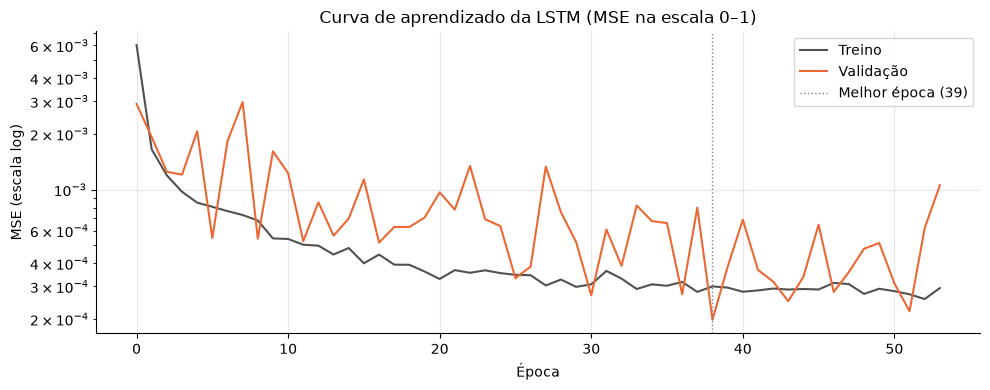

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(historico.history["loss"],     color="#52514e", lw=1.5, label="Treino")
ax.plot(historico.history["val_loss"], color="#eb6834", lw=1.5, label="Validação")
ax.axvline(melhor, color="gray", ls=":", lw=1, label=f"Melhor época ({melhor + 1})")
ax.set_yscale("log")
ax.set_title("Curva de aprendizado da LSTM (MSE na escala 0–1)")
ax.set_xlabel("Época")
ax.set_ylabel("MSE (escala log)")
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend()
plt.tight_layout()
plt.show()

## 5. Previsão no período de teste e métricas

A rede prevê cada dia do teste a partir da janela dos **30 dias anteriores observados** (previsão *um passo à frente*, $t+1$).
As previsões saem na escala 0–1 e são convertidas de volta para **R\$ / saca 50 kg** com `escala_y.inverse_transform`.

> **Atenção (comparação com SARIMA/SARIMAX):** os modelos estatísticos previram os 30 dias **de uma só vez**, sem ver nenhum preço do teste.
> Aqui, cada previsão usa o preço real até o dia anterior. O horizonte efetivo é de **1 dia**, o que tende a favorecer a LSTM
> na comparação das métricas. As exógenas também são as **observadas** (chuva, câmbio), como no SARIMAX.

As métricas seguem as mesmas fórmulas dos notebooks anteriores:

| Métrica | Fórmula | O que mede |
|---|---|---|
| **RMSE** | $\sqrt{\frac{1}{n}\sum (y_t - \hat{y}_t)^2}$ | erro em R\$; pune mais os erros grandes |
| **MAE** | $\frac{1}{n}\sum \lvert y_t - \hat{y}_t \rvert$ | "em média, erramos X reais por dia" |
| **MAPE** | $\frac{100}{n}\sum \left\lvert \frac{y_t - \hat{y}_t}{y_t} \right\rvert$ | "em média, erramos X% do preço" |

In [9]:
# Previsão (escala 0-1) e retorno para R$
prev_esc = modelo.predict(X_te, verbose=0)                       # (30, 1)
y_prev   = pd.Series(escala_y.inverse_transform(prev_esc).ravel(), index=datas_te, name="previsto")
y_teste  = teste[ALVO]

assert (y_prev.index == y_teste.index).all()
# Sanidade: desfazer a escala do rótulo deve devolver exatamente o preço real
assert np.allclose(escala_y.inverse_transform(y_te.reshape(-1, 1)).ravel(), y_teste.values)

# Métricas calculadas diretamente pelas fórmulas
erro = y_teste.values - y_prev.values
rmse = np.sqrt(np.mean(erro ** 2))
mae  = np.mean(np.abs(erro))
mape = np.mean(np.abs(erro / y_teste.values)) * 100

print(f"RMSE = R$ {rmse:.2f}")
print(f"MAE  = R$ {mae:.2f}")
print(f"MAPE = {mape:.2f}%")

# Referência ingênua: "amanhã = hoje" (mesmo horizonte de 1 dia)
ingenuo = dados[ALVO].shift(1).loc[y_teste.index]
erro_ing = y_teste.values - ingenuo.values
print(f"\nReferência ingênua (preço de ontem): RMSE = R$ {np.sqrt(np.mean(erro_ing**2)):.2f} | "
      f"MAE = R$ {np.mean(np.abs(erro_ing)):.2f} | MAPE = {np.mean(np.abs(erro_ing / y_teste.values))*100:.2f}%")

RMSE = R$ 0.22
MAE  = R$ 0.18
MAPE = 0.33%

Referência ingênua (preço de ontem): RMSE = R$ 0.13 | MAE = R$ 0.07 | MAPE = 0.13%


Tabela dia a dia do período de teste:

In [10]:
comparacao = pd.DataFrame({
    "Real (R$)":     y_teste,
    "Previsto (R$)": y_prev,
    "Erro (R$)":     y_teste - y_prev,
}).round(2)
comparacao.index = comparacao.index.strftime("%d/%m/%Y")
comparacao

,Real (R$),Previsto (R$),Erro (R$)
data,,,
01/02/2026,54.01,53.770000,0.24
02/02/2026,54.00,53.799999,0.20
03/02/2026,54.26,54.009998,0.25
04/02/2026,54.29,54.090000,0.20
05/02/2026,54.30,54.299999,0.00
06/02/2026,54.35,54.419998,-0.07
07/02/2026,54.35,54.570000,-0.22
08/02/2026,54.35,54.680000,-0.33
09/02/2026,54.44,54.750000,-0.31


## 6. Visualização gráfica e exportação

### 6.1 Gráfico: Real vs. Previsão LSTM

Mesmo padrão dos gráficos do SARIMA/SARIMAX: últimos 90 dias do treino, seguidos dos 30 dias de teste.
A LSTM não fornece intervalo de confiança nativamente, por isso o gráfico mostra apenas a previsão pontual.

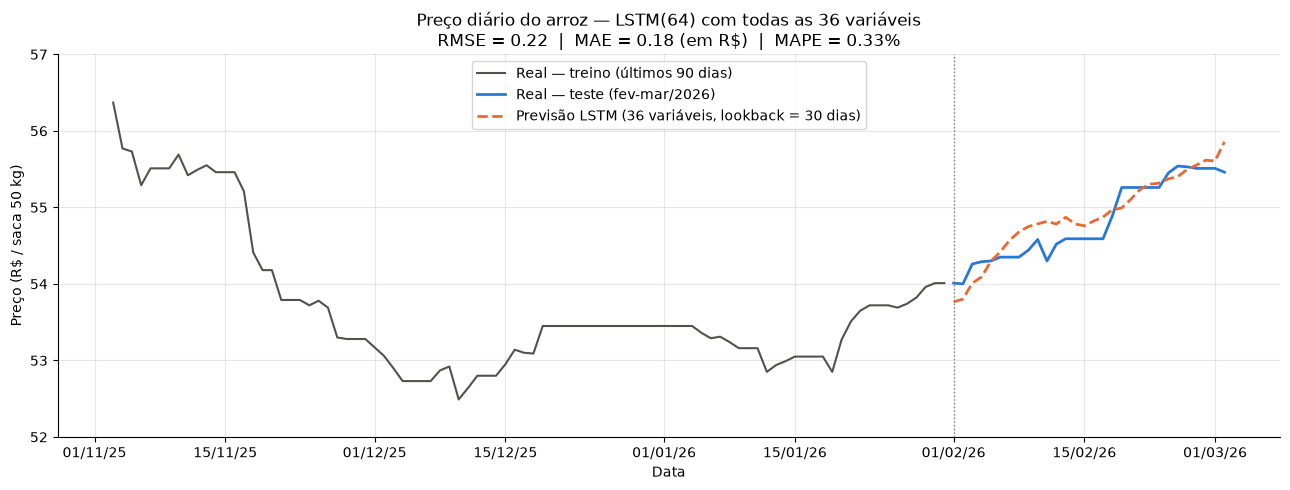

In [11]:
contexto = treino[ALVO].iloc[-90:]   # últimos 90 dias do treino

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(contexto, color="#52514e", lw=1.5, label="Real — treino (últimos 90 dias)")
ax.plot(y_teste,  color="#2a78d6", lw=2,   label="Real — teste (fev-mar/2026)")
ax.plot(y_prev,   color="#eb6834", lw=2, ls="--", label=f"Previsão LSTM (36 variáveis, lookback = {LOOKBACK} dias)")
ax.axvline(y_teste.index[0], color="gray", ls=":", lw=1)   # linha do corte treino/teste

ax.set_title(f"Preço diário do arroz — LSTM(64) com todas as 36 variáveis\n"
             f"RMSE = {rmse:.2f}  |  MAE = {mae:.2f} (em R$)  |  MAPE = {mape:.2f}%")
ax.set_xlabel("Data")
ax.set_ylabel("Preço (R$ / saca 50 kg)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m/%y"))
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(52, 57)   # mesma escala nos gráficos de SARIMA, SARIMAX e LSTM, para comparação visual justa
ax.legend(loc="upper center")

plt.tight_layout()
plt.savefig(f"{PASTA_SAIDA}/lstm_previsao.png", dpi=150)
plt.show()

### 6.2 Exportação das métricas

Mesmo formato dos demais modelos, para montar a tabela comparativa.

In [12]:
pd.DataFrame({"modelo": ["LSTM"], "RMSE": [rmse], "MAE": [mae], "MAPE": [mape]}) \
  .round(4).to_csv(f"{PASTA_SAIDA}/metricas_lstm.csv", index=False)

print(f"Gráfico salvo em {PASTA_SAIDA}/lstm_previsao.png")
print(f"Métricas salvas em {PASTA_SAIDA}/metricas_lstm.csv")
pd.read_csv(f"{PASTA_SAIDA}/metricas_lstm.csv")

Gráfico salvo em outputs/lstm_previsao.png
Métricas salvas em outputs/metricas_lstm.csv


,modelo,RMSE,MAE,MAPE
0,LSTM,0.2181,0.1825,0.3339


### 6.3 Comparação com os modelos estatísticos

Lê os CSVs de métricas já gerados na pasta `outputs/`. Lembre da diferença de horizonte descrita na seção 5:
SARIMA/SARIMAX previram 30 dias de uma vez; a LSTM, um dia à frente com histórico observado.

In [13]:
arquivos = ["metricas_sarima.csv", "metricas_sarimax.csv", "metricas_lstm.csv"]
tabela = pd.concat([pd.read_csv(f"{PASTA_SAIDA}/{a}") for a in arquivos if os.path.exists(f"{PASTA_SAIDA}/{a}")],
                   ignore_index=True)
tabela

,modelo,RMSE,MAE,MAPE
0,SARIMA,0.4658,0.3538,0.6405
1,SARIMAX,0.4655,0.3535,0.6400
2,LSTM,0.2181,0.1825,0.3339
